In [36]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [37]:
# Load Iris Dataset

df = pd.read_csv("iris.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [38]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [39]:
# Dataset shape

print("Dataset Shape:", df.shape)

# Dataset information

df.info()

Dataset Shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [40]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [41]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [42]:
print("Flower Species:")
print(df["species"].value_counts())

Flower Species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


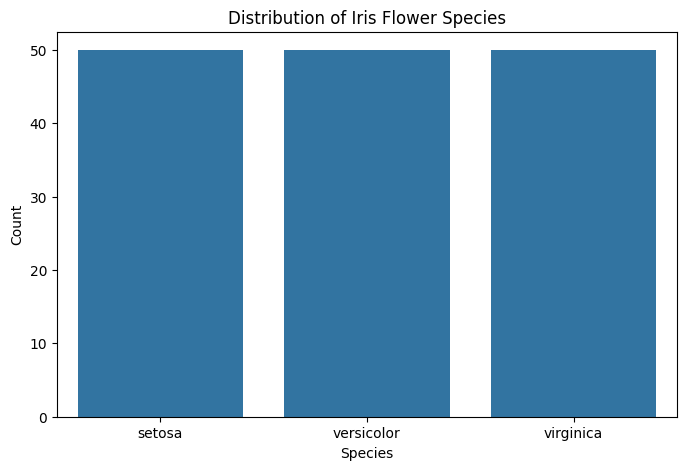

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

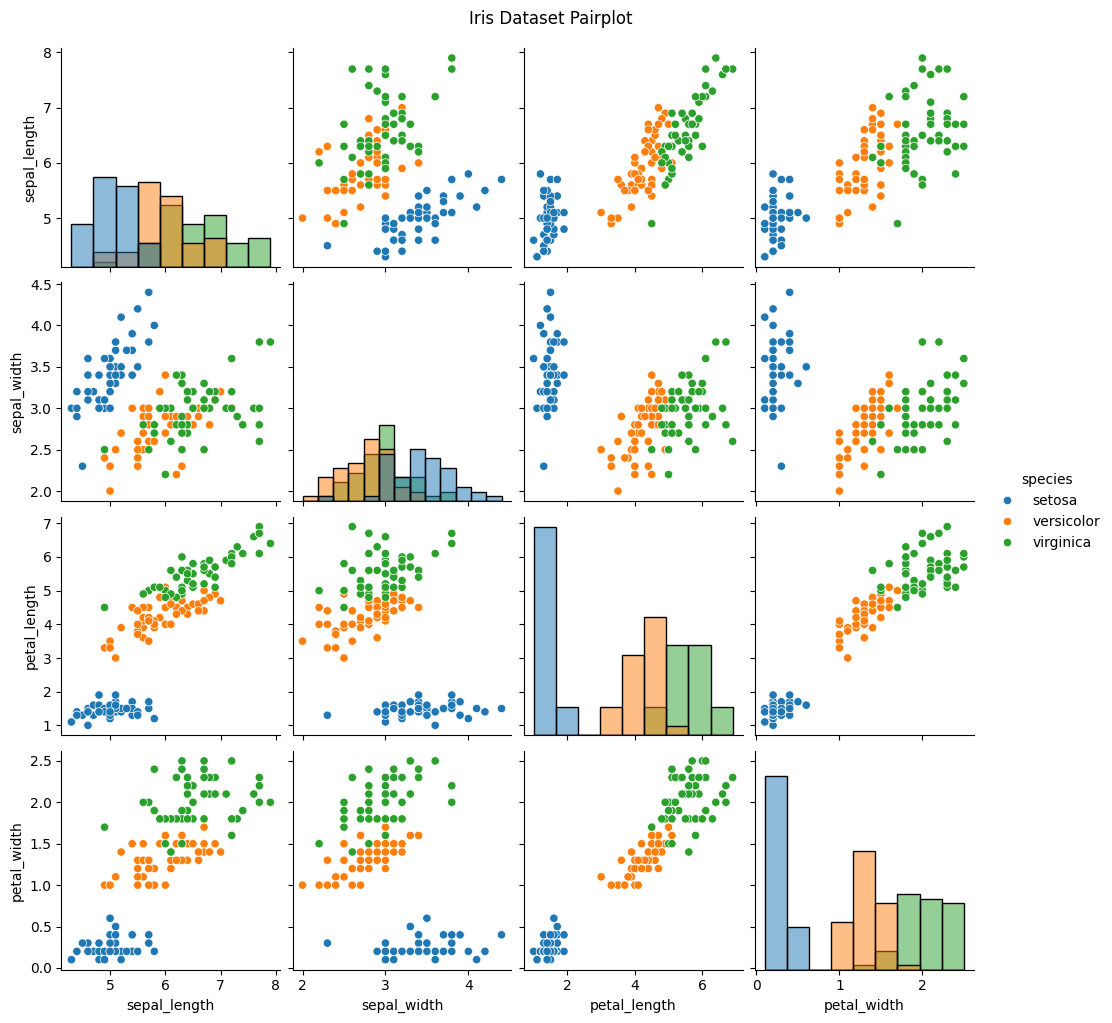

In [44]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset Pairplot", y=1.02)

plt.show()

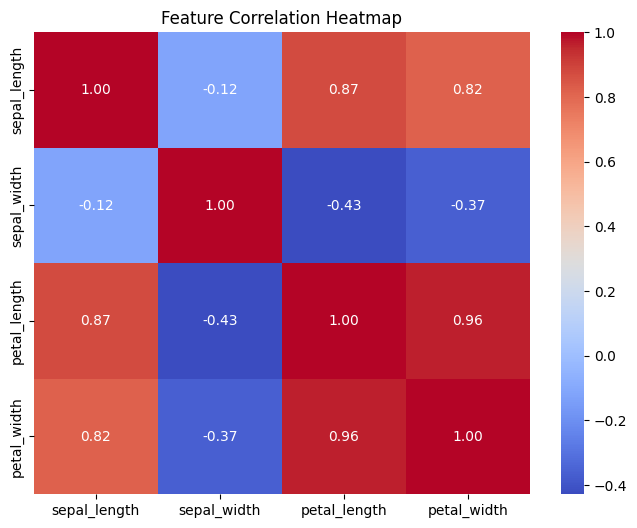

In [45]:
plt.figure(figsize=(8, 6))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [46]:
# Separate features and target

X = df.drop("species", axis=1)
y = df["species"]

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Features (X):


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target (y):


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object

In [47]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Encoded Classes:")
print(label_encoder.classes_)

print("\nEncoded Values:")
print(y_encoded[:10])

Encoded Classes:
['setosa' 'versicolor' 'virginica']

Encoded Values:
[0 0 0 0 0 0 0 0 0 0]


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [50]:
print("Training Data Mean:")
print(X_train_scaled.mean(axis=0))

print("\nTraining Data Standard Deviation:")
print(X_train_scaled.std(axis=0))

Training Data Mean:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]

Training Data Standard Deviation:
[1. 1. 1. 1.]


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

print("ML algorithms imported successfully!")

ML algorithms imported successfully!


In [52]:
# Initialize Logistic Regression

log_model = LogisticRegression(max_iter=200)

# Train the model

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [53]:
# Initialize Decision Tree

tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model

tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [54]:
# Logistic Regression predictions

log_predictions = log_model.predict(X_test_scaled)

# Decision Tree predictions

tree_predictions = tree_model.predict(X_test_scaled)

print("Predictions completed!")

print("\nLogistic Regression:")
print(log_predictions)

print("\nDecision Tree:")
print(tree_predictions)

Predictions completed!

Logistic Regression:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Decision Tree:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [55]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test, log_predictions)

tree_accuracy = accuracy_score(y_test, tree_predictions)

print("MODEL ACCURACY COMPARISON")

print("Logistic Regression:", round(log_accuracy * 100, 2), "%")

print("Decision Tree:", round(tree_accuracy * 100, 2), "%")

MODEL ACCURACY COMPARISON
Logistic Regression: 93.33 %
Decision Tree: 93.33 %


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [57]:
print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    log_predictions,
    target_names=label_encoder.classes_
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [58]:
print("DECISION TREE REPORT")

print(classification_report(
    y_test,
    tree_predictions,
    target_names=label_encoder.classes_
))

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



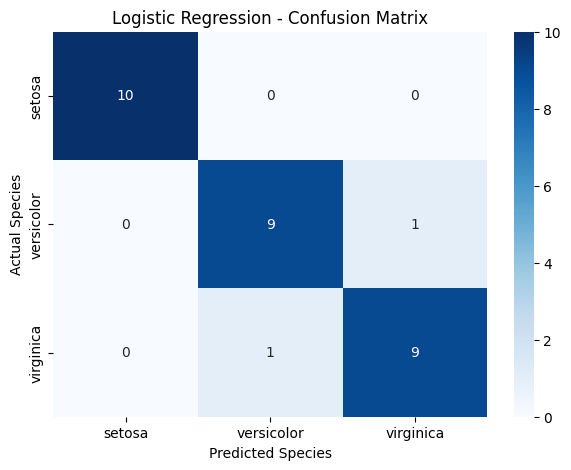

In [59]:
log_cm = confusion_matrix(y_test, log_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    log_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

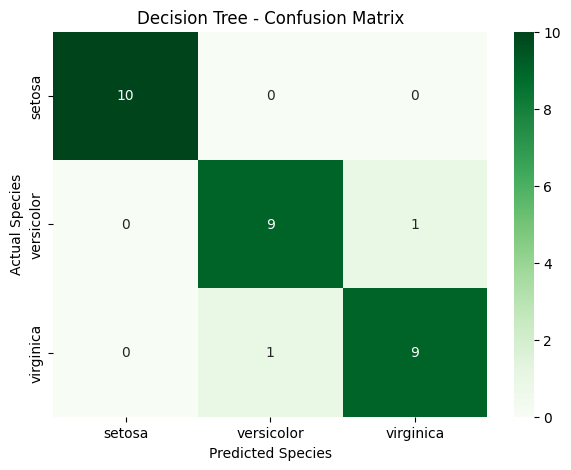

In [60]:
tree_cm = confusion_matrix(y_test, tree_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [61]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "Precision": [
        precision_score(y_test, log_predictions, average="weighted"),
        precision_score(y_test, tree_predictions, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, log_predictions, average="weighted"),
        recall_score(y_test, tree_predictions, average="weighted")
    ],
    "F1 Score": [
        f1_score(y_test, log_predictions, average="weighted"),
        f1_score(y_test, tree_predictions, average="weighted")
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


In [62]:
from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    predictions = model.predict(grid)
    predictions = predictions.reshape(xx.shape)

    plt.figure(figsize=(9, 6))

    plt.contourf(
        xx, yy, predictions,
        alpha=0.3,
        cmap=ListedColormap(["#FFAAAA", "#AAFFAA", "#AAAAFF"])
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        edgecolor="black"
    )

    plt.xlabel("Petal Length (Standardized)")
    plt.ylabel("Petal Width (Standardized)")
    plt.title(title)

    plt.show()

In [63]:
# Select Petal Length and Petal Width

X_petal = df[["petal_length", "petal_width"]]

# Split dataset

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_petal,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Normalize features

scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train Logistic Regression

log_model_2d = LogisticRegression(max_iter=200)
log_model_2d.fit(X_train_2d_scaled, y_train_2d)

# Train Decision Tree

tree_model_2d = DecisionTreeClassifier(random_state=42)
tree_model_2d.fit(X_train_2d_scaled, y_train_2d)

print("Two-feature models trained successfully!")

Two-feature models trained successfully!


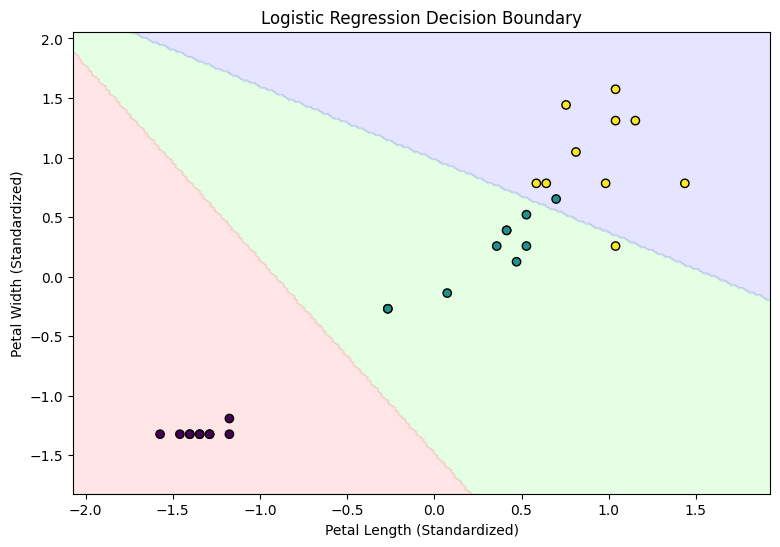

In [64]:
plot_decision_boundary(
    log_model_2d,
    X_test_2d_scaled,
    y_test_2d,
    "Logistic Regression Decision Boundary"
)

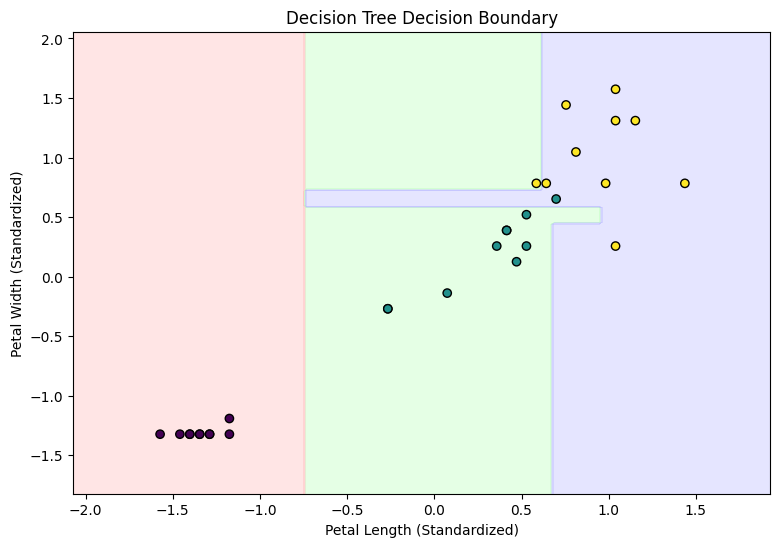

In [65]:
plot_decision_boundary(
    tree_model_2d,
    X_test_2d_scaled,
    y_test_2d,
    "Decision Tree Decision Boundary"
)